# 01. 결과 정리: 수어 알파벳 인식, CNN vs 손 관절 RF

이미 계산된 결과(`results/`)와 데이터로 실험 과정을 셀 단위로 따라간다. 무거운 학습은 하지 않는다.

- 실행 순서와 명령: `README.md`
- 근거 문서: `docs/REPORT.md`, `docs/experiments/EXP-001…005`

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from signlight import config as C
from signlight.data import load_index, synth_subset
from signlight.images import load_rgb
from signlight.perturb import apply

plt.rcParams['font.family'] = ['AppleGothic', 'NanumGothic', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.precision', 3)
print('대상 클래스', len(C.TARGET_CLASSES), ''.join(C.TARGET_CLASSES))

대상 클래스 24 ABCDEFGHIKLMNOPQRSTUVWXY


## 1. 데이터와 분할 (EXP-001)
Kaggle ASL Alphabet은 영상 연속 프레임이라 거의 같은 사진이 많다. 비슷한 사진끼리 군집으로 묶어, 군집 단위로 train/val/test를 나눴다.

In [2]:
idx = load_index()
stats = json.loads((C.RESULTS_DIR / 'split_stats.json').read_text())
print('전체', stats['n'], '| split', stats['split'], '| 군집 수', stats['n_clusters'])
pd.DataFrame({k: {'군집 수': v['n_clusters'], '최대 군집': v['max_cluster'], **v['split']}
              for k, v in stats['per_class'].items()}).T.head(8)

전체 72000 | split {'train': 43449, 'val': 14308, 'test': 14243} | 군집 수 3160


,군집 수,최대 군집,train,val,test
A,69,1000,1652,1000,348
B,65,1000,1500,500,1000
C,54,997,1934,299,767
D,32,997,1974,720,306
E,87,995,1909,458,633
F,224,737,1869,565,566
G,89,962,1522,516,962
H,59,972,2227,286,487


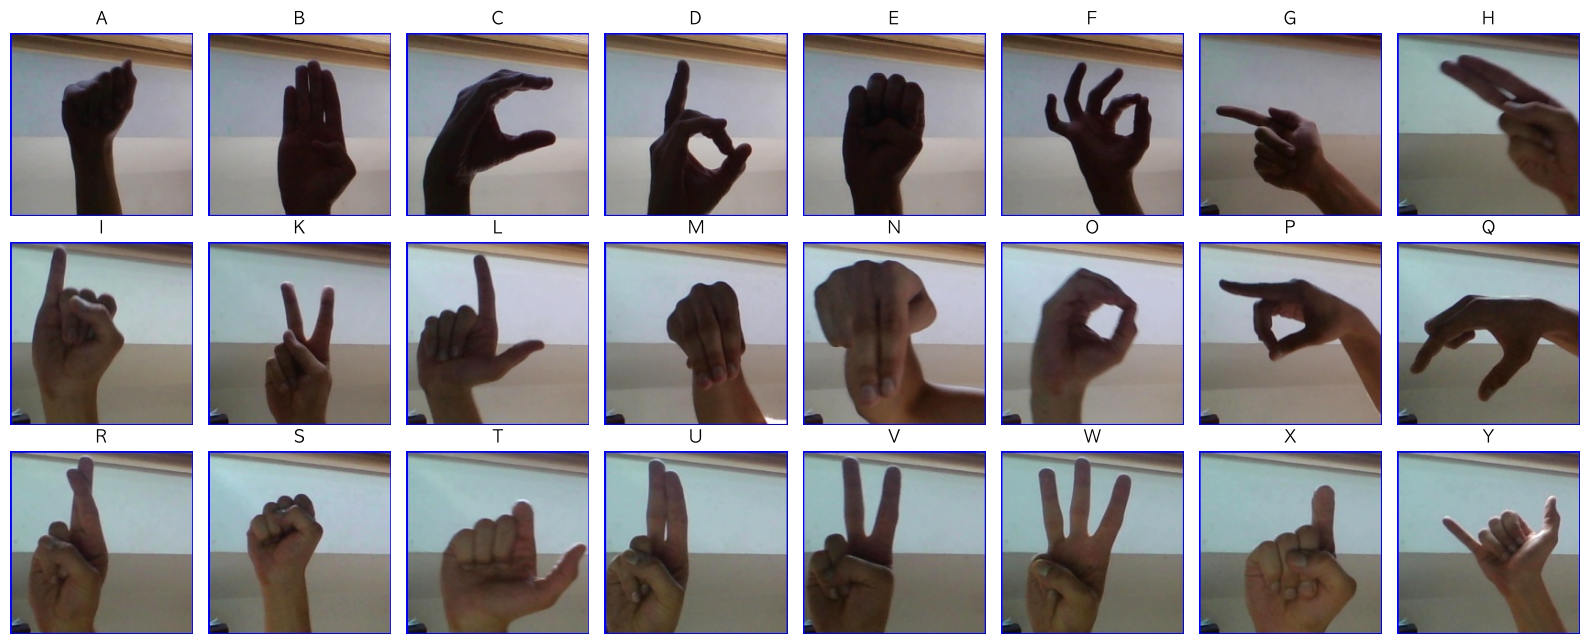

In [3]:
# 클래스별 예시 사진 1장씩
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, label in zip(axes.ravel(), C.TARGET_CLASSES):
    p = idx[idx['label'] == label]['relpath'].iloc[0]
    ax.imshow(load_rgb(C.ASL_ROOT / p)); ax.set_title(label); ax.axis('off')
plt.tight_layout()

## 2. 합성 환경 변형
기획안의 실험 1~4를 합성 변형으로 근사했다. 같은 (조건, 사진, key)는 항상 같은 결과를 내므로, RF(로컬)와 CNN(Colab)이 같은 사진으로 평가받는다.

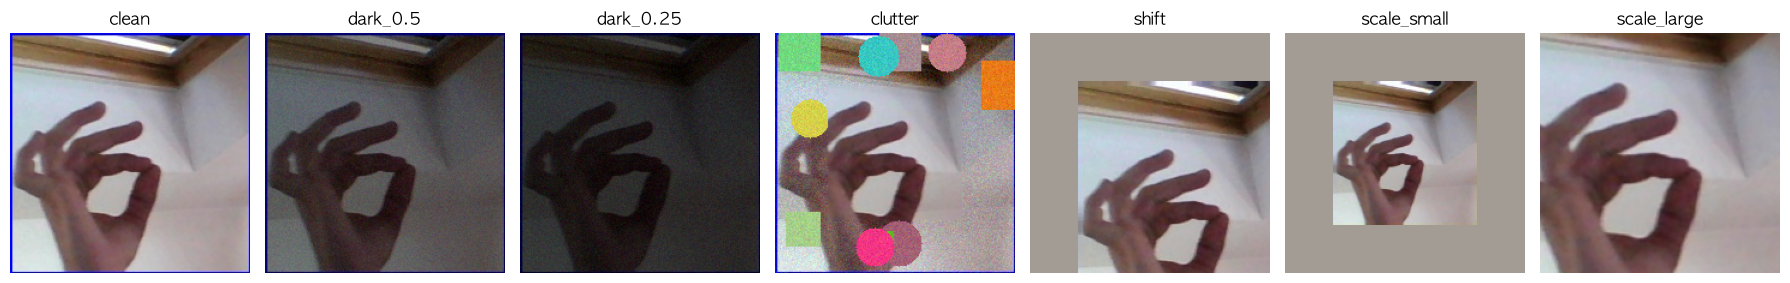

In [4]:
sub = synth_subset(idx)
ex = sub[sub['label'] == 'F']  # 검출이 잘 되는 클래스(EXP-002: F 20/20)를 예시로
key, rel = ex.index[0], ex['relpath'].iloc[0]
img = load_rgb(C.ASL_ROOT / rel)
fig, axes = plt.subplots(1, len(C.SYNTH_CONDITIONS), figsize=(18, 3))
for ax, cond in zip(axes, C.SYNTH_CONDITIONS):
    ax.imshow(apply(cond, img, key)); ax.set_title(cond); ax.axis('off')
plt.tight_layout()

## 3. MediaPipe 손 관절 검출 (EXP-002)
RF는 MediaPipe가 찾은 관절 21점으로 분류한다. 손을 못 찾으면 오답으로 센다.

INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x77d63c02a0, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x77d63c0360, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
W0000 00:00:1795321568.023565 5537427 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
INFO: [accelerator_registry.cc:43] DestroyAccelerator: ptr=0x77d63c02a0, name=CpuAccelerator
INF

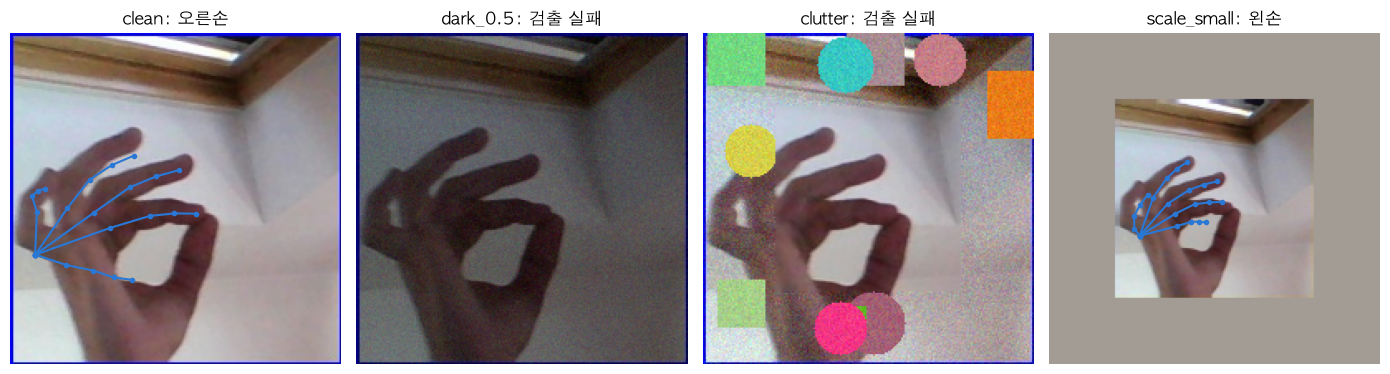

In [5]:
from signlight.landmarks import HandDetector

CHAINS = [(0, 1, 2, 3, 4), (0, 5, 6, 7, 8), (0, 9, 10, 11, 12), (0, 13, 14, 15, 16), (0, 17, 18, 19, 20)]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
with HandDetector() as det:
    for ax, cond in zip(axes, ['clean', 'dark_0.5', 'clutter', 'scale_small']):
        im = apply(cond, img, key)
        lm, right = det.detect(im)
        ax.imshow(im); ax.axis('off')
        if lm is None:
            ax.set_title(f'{cond}: 검출 실패')
            continue
        xy = lm[:, :2] * [im.shape[1], im.shape[0]]
        for ch in CHAINS:
            ax.plot(xy[list(ch), 0], xy[list(ch), 1], '-o', ms=3, lw=1.5, color='#2a78d6')
        ax.set_title(f"{cond}: {'오른손' if right else '왼손'}")
plt.tight_layout()

In [6]:
det = pd.read_csv(C.RESULTS_DIR / 'detection_rate.csv')
table = det.pivot(index='label', columns='split', values='det_rate')[['train', 'val', 'test']]
print('전체 검출률(가중):', round((det['n'] * det['det_rate']).sum() / det['n'].sum(), 3))
table.sort_values('test').head(6)  # test 검출률이 낮은 클래스: 촬영 회차 효과(EXP-005)

전체 검출률(가중): 0.802


split,train,val,test
label,,,
X,0.889,0.859,0.163
H,0.982,0.689,0.179
Q,0.783,1.000,0.216
A,0.679,0.999,0.503
M,0.735,0.343,0.691
C,0.714,0.692,0.694


## 4. 환경별 정확도 (EXP-003, 004)
e2e 정확도다(검출 실패 = 오답). CNN은 시드 3개 평균이다.

In [7]:
mean = pd.read_csv(C.RESULTS_DIR / 'summary_seed_mean.csv')
synth = mean[mean['testset'] == 'synth'].pivot(index='condition', columns='model', values='acc')
synth.loc[C.SYNTH_CONDITIONS, ['rf_geom', 'dt_geom', 'cnn_plain', 'cnn_aug', 'rf_geom_clahe']]

model,rf_geom,dt_geom,cnn_plain,cnn_aug,rf_geom_clahe
condition,,,,,
clean,0.717,0.680,0.632,0.576,0.551
dark_0.5,0.193,0.172,0.213,0.383,0.094
dark_0.25,0.047,0.033,0.042,0.194,0.010
clutter,0.421,0.380,0.187,0.199,0.307
shift,0.534,0.482,0.385,0.486,0.411
scale_small,0.687,0.647,0.237,0.316,0.625
scale_large,0.450,0.415,0.513,0.505,0.293


In [8]:
drop = pd.read_csv(C.RESULTS_DIR / 'drop.csv')
d = drop[drop['testset'] == 'synth'].groupby(['condition', 'model'])['drop_pp'].mean().unstack()
d.loc[C.SYNTH_CONDITIONS[1:], ['rf_geom', 'dt_geom', 'cnn_plain', 'cnn_aug']].round(1)  # 원본 대비 감소 폭(%p)

model,rf_geom,dt_geom,cnn_plain,cnn_aug
condition,,,,
dark_0.5,52.3,50.9,41.9,19.3
dark_0.25,67.0,64.8,59.0,38.2
clutter,29.6,30.0,44.5,37.7
shift,18.2,19.8,24.8,9.0
scale_small,3.0,3.3,39.6,26.0
scale_large,26.7,26.5,11.9,7.1


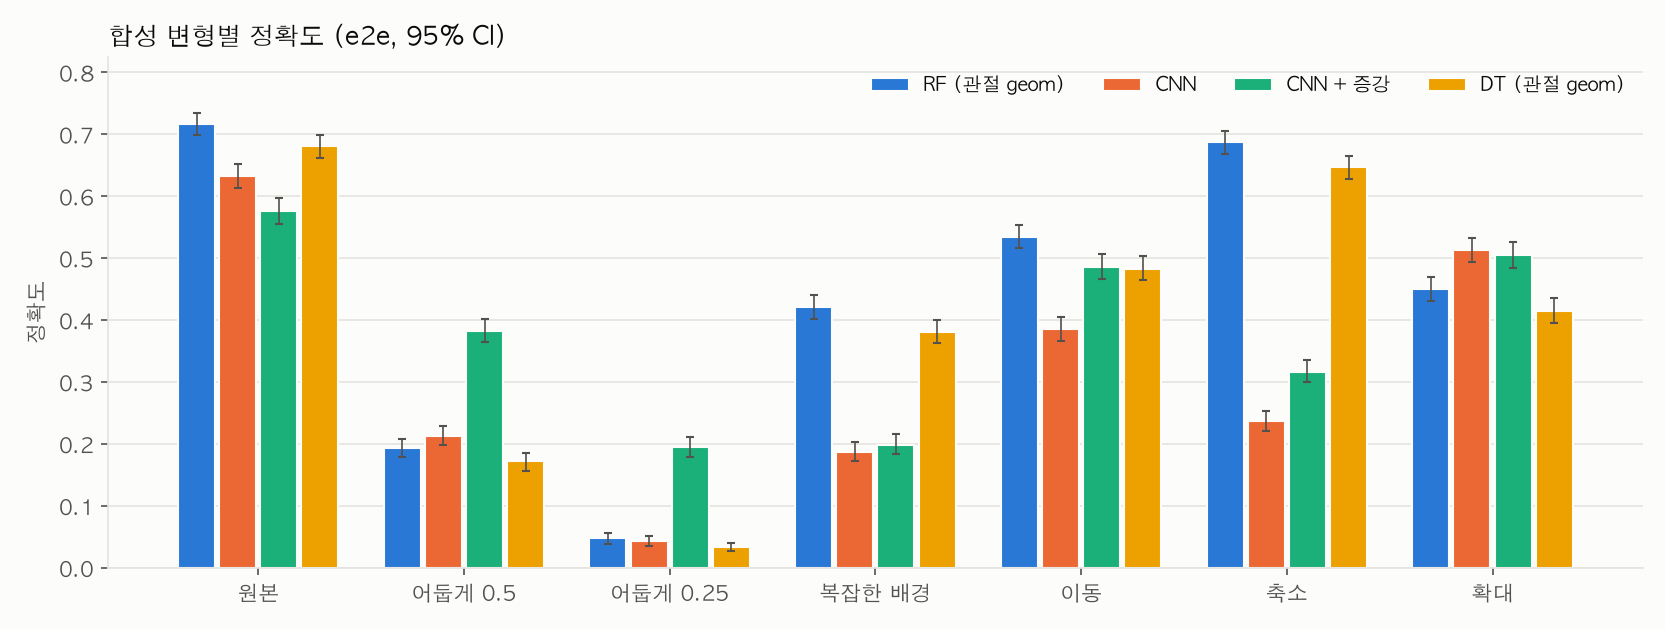

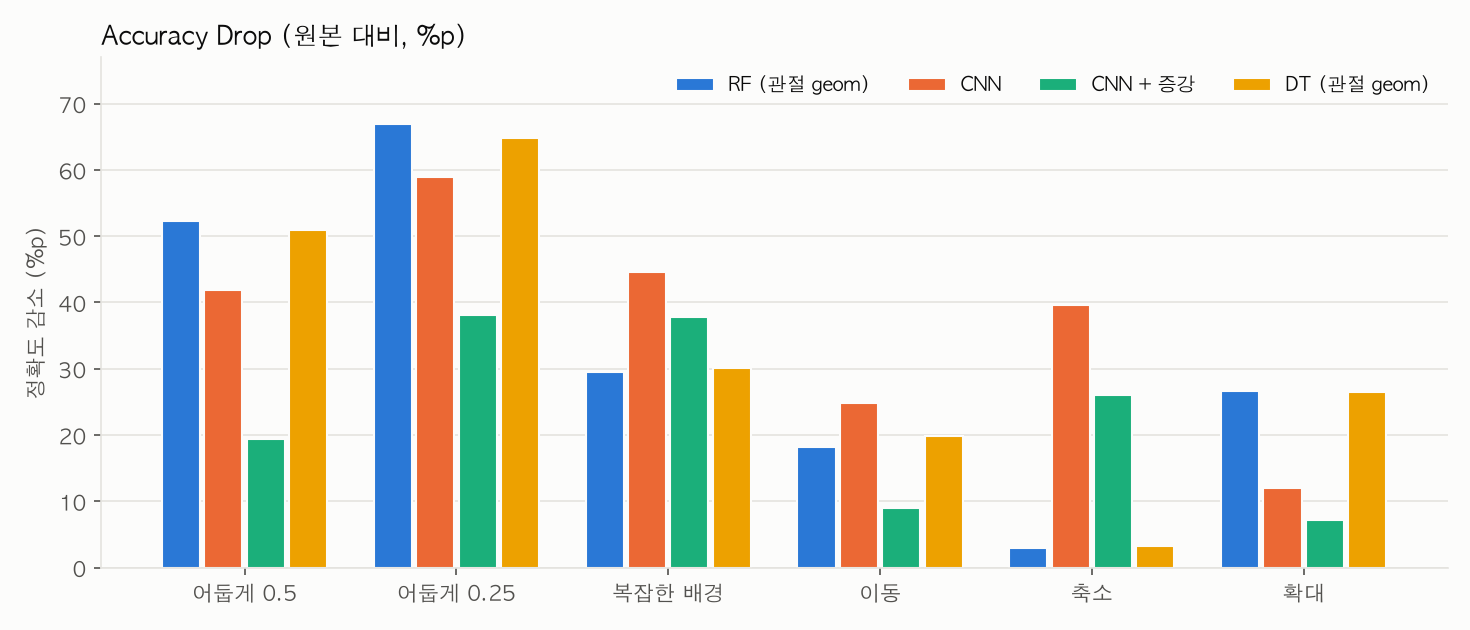

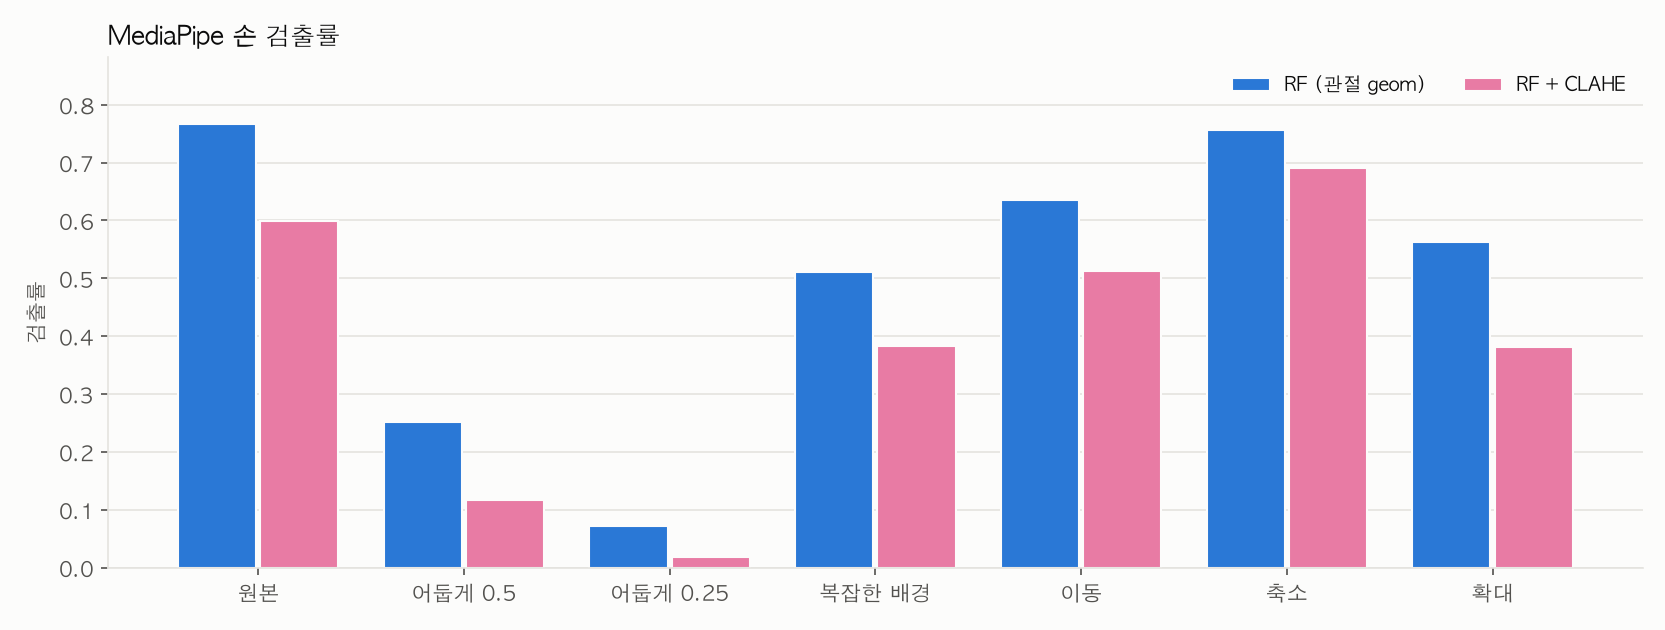

In [9]:
for name in ['acc_by_condition_synth', 'drop_by_condition_synth', 'detection_rate_synth']:
    display(Image(filename=str(C.FIGURES_DIR / f'{name}.png'), width=900))

## 5. 혼동행렬과 오류 분석 (EXP-005)

In [10]:
from signlight.evaluate import confusion, load_preds

def top_confusions(files, k=6):
    cm = sum(confusion(*load_preds(C.PREDS_DIR / f), 24) for f in files)
    off = cm[:, :24].copy(); np.fill_diagonal(off, 0)
    rate = off / cm.sum(1, keepdims=True)
    pairs = sorted(((rate[i, j], C.TARGET_CLASSES[i], C.TARGET_CLASSES[j]) for i in range(24) for j in range(24) if off[i, j]), reverse=True)[:k]
    return [(f'{a}→{b}', round(float(r), 2)) for r, a, b in pairs], round(float(cm[:, 24].sum() / cm.sum()), 3)

print('RF  ', *top_confusions(['rf_geom__synth__clean.npz']))
print('CNN+aug', *top_confusions([f'cnn_aug__synth__clean__s{s}.npz' for s in C.CNN_SEEDS]))

RF   [('D→O', 0.23), ('R→U', 0.13), ('N→M', 0.09), ('V→U', 0.05), ('A→M', 0.05), ('U→D', 0.04)] 0.233
CNN+aug [('H→G', 1.0), ('G→H', 0.74), ('S→X', 0.59), ('X→R', 0.55), ('I→K', 0.48), ('V→K', 0.47)] 0.0


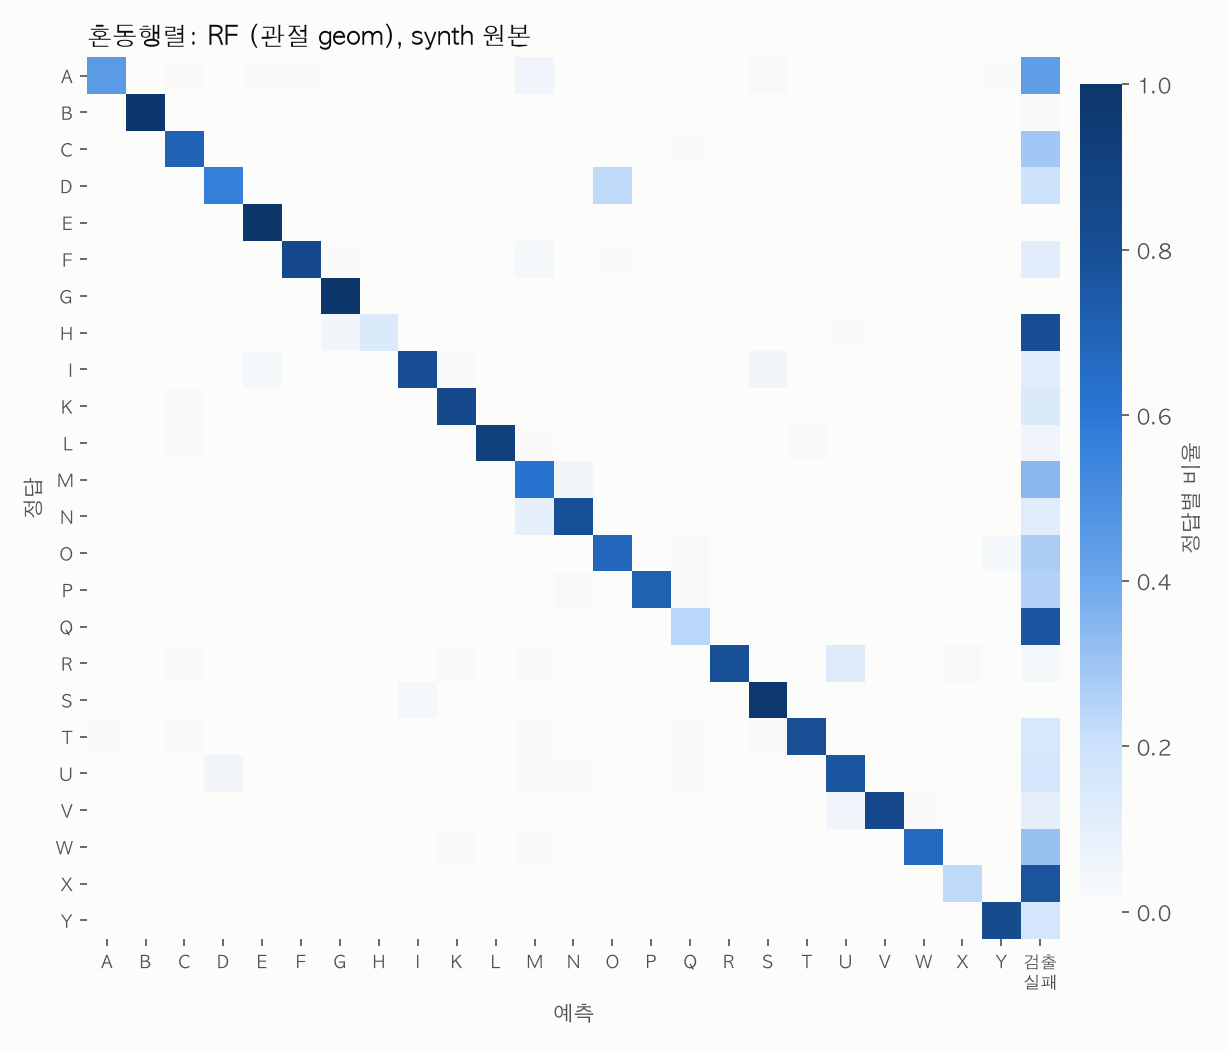

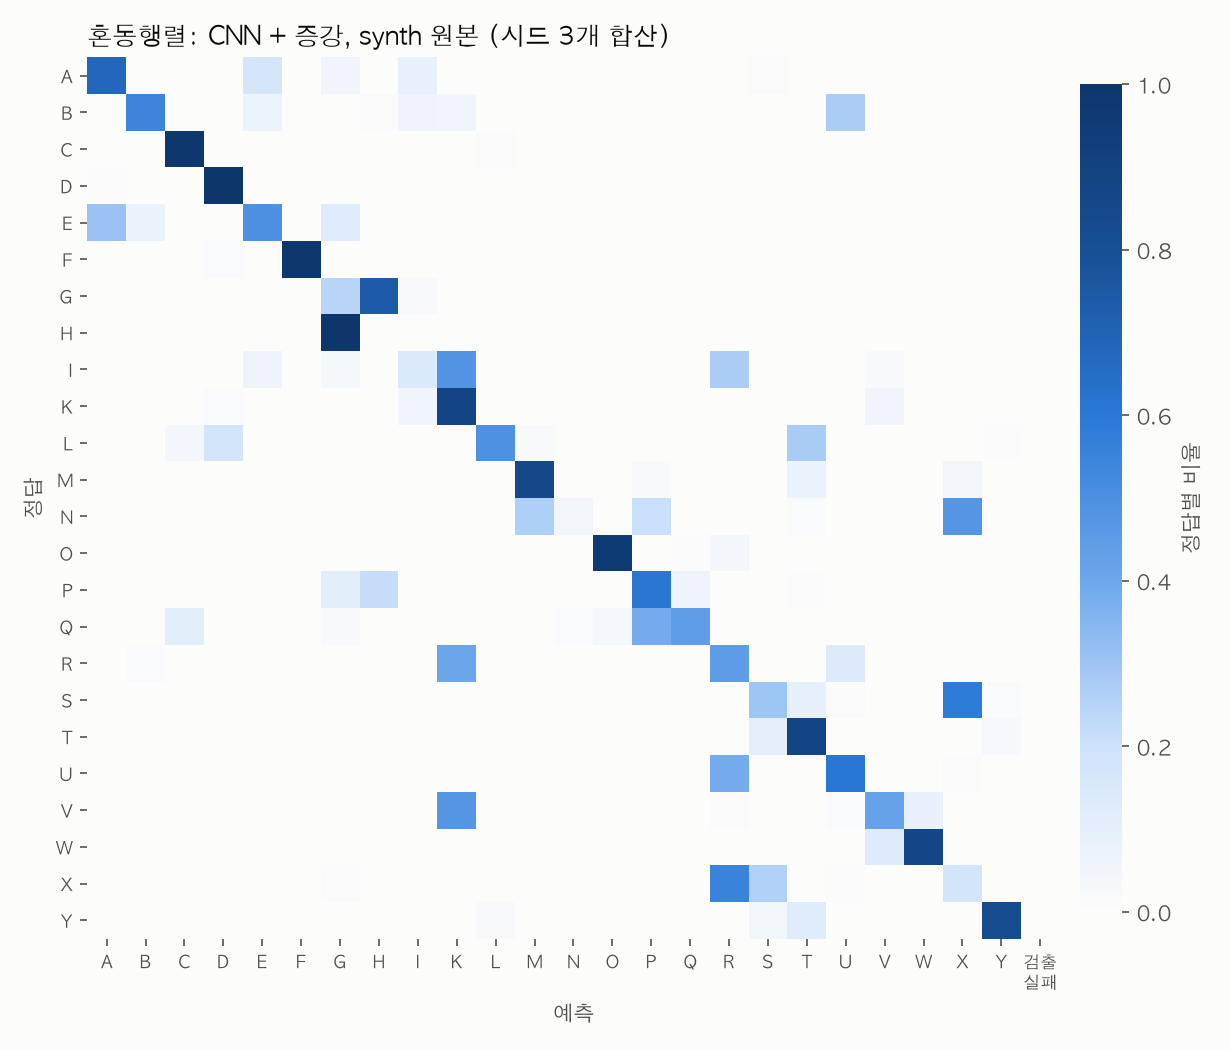

In [11]:
for name in ['confusion_rf_geom_synth', 'confusion_cnn_aug_synth']:
    display(Image(filename=str(C.FIGURES_DIR / f'{name}.png'), width=650))

## 6. 직접 촬영 테스트셋 상태
팀원 사진이 `data/custom_test/`에 들어오면 `docs/REPORT.md` 6절의 명령으로 평가한다.

In [12]:
from signlight.custom_test import report, scan

df = scan()
print('직접 촬영 사진:', len(df), '장')
if len(df):
    display(report(df))

직접 촬영 사진: 0 장
